# Gaussian HMM training

Trains a Gaussian hidden Markov model on the simulated weather in `simulated_dataset/`.

## 1. Load the simulated dataset

`load_simulated` (in `modules/dataset/dataset.py`) reads the monthly CSVs written by `simulation.ipynb` and:

- reads only the months that overlap `START`–`END`
- adds `rain_flag` (precipitation detector) from the raw `dataset/` files if the CSVs lack it
- fails if any value is NaN or infinite
- numbers the unbroken stretches of data in `segment`: a gap starts a new segment, so an HMM sequence never runs across missing data

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from modules.dataset.dataset import load_simulated

In [2]:
SIM_DIR = "simulated_dataset"
START, END = None, None   # e.g. "2024-06-01", "2024-10-01"; None = everything

data = load_simulated(SIM_DIR, start=START, end=END)
step = data.attrs["step"]
print(f"{len(data.attrs['files'])} files, {len(data):,} rows at {step.total_seconds():.0f}s steps")
print(f"{data.index.min()} → {data.index.max()}")
data.head()

19 files, 2,385,742 rows at 20s steps
2024-01-01 00:01:00 → 2026-07-07 23:58:40


,temperature,pressure,sea_pressure,humidity,wind_speed,rain,wind_dir,wind_u,wind_v,rain_flag,segment
timestamp,,,,,,,,,,,
2024-01-01 00:01:00,0.700000,1018.8,1025.100000,96.0,0.634568,0.0,48.166641,-0.472809,-0.423235,0.0,0
2024-01-01 00:01:20,0.723457,1018.8,1025.100000,96.0,0.634568,0.0,47.561591,-0.468313,-0.428205,0.0,0
2024-01-01 00:01:40,0.758025,1018.8,1025.100000,96.0,0.530864,0.0,53.760634,-0.428171,-0.313826,0.0,0
2024-01-01 00:02:00,0.800000,1018.8,1025.100000,96.0,0.246914,0.0,70.314724,-0.232483,-0.083174,0.0,0
2024-01-01 00:02:20,0.871605,1018.8,1025.074074,96.0,0.143210,0.0,76.511896,-0.139260,-0.033403,0.0,0


In [3]:
data.tail()

,temperature,pressure,sea_pressure,humidity,wind_speed,rain,wind_dir,wind_u,wind_v,rain_flag,segment
timestamp,,,,,,,,,,,
2026-07-07 23:57:20,25.8,1003.300000,1008.900000,74.022222,2.627160,0.0,205.407822,1.127205,2.373053,0.0,94
2026-07-07 23:57:40,25.8,1003.300000,1008.900000,73.877778,2.623457,0.0,207.313513,1.203797,2.330965,0.0,94
2026-07-07 23:58:00,25.8,1003.300000,1008.900000,73.800000,2.546914,0.0,212.851556,1.381610,2.139608,0.0,94
2026-07-07 23:58:20,25.8,1003.314815,1008.914815,73.803704,2.476543,0.0,217.415320,1.504719,1.967000,0.0,94
2026-07-07 23:58:40,25.8,1003.351852,1008.951852,73.829630,2.476543,0.0,217.415320,1.504719,1.967000,0.0,94


### Segments

Each segment is one unbroken sequence. Later these become hmmlearn's `lengths`.

In [4]:
segments = (data.groupby("segment")
                .agg(start=("segment", lambda s: s.index.min()),
                     end=("segment", lambda s: s.index.max()),
                     rows=("segment", "size")))
segments["hours"] = (segments["rows"] * step / pd.Timedelta(hours=1)).round(1)
print(f"{len(segments)} segments; rows per segment: "
      f"min {segments['rows'].min():,}, median {int(segments['rows'].median()):,}, max {segments['rows'].max():,}")
segments.sort_values("rows").head(10)

95 segments; rows per segment: min 3, median 14,829, max 145,395


,start,end,rows,hours
segment,,,,
34,2024-07-19 03:41:00,2024-07-19 03:41:40,3,0.0
35,2024-07-19 03:52:00,2024-07-19 03:52:40,3,0.0
7,2024-02-29 00:15:00,2024-02-29 00:15:40,3,0.0
9,2024-02-29 00:31:00,2024-02-29 00:33:40,9,0.0
33,2024-07-19 03:32:00,2024-07-19 03:35:40,12,0.1
13,2024-02-29 02:51:00,2024-02-29 02:57:40,21,0.1
8,2024-02-29 00:18:00,2024-02-29 00:28:40,33,0.2
12,2024-02-29 02:19:00,2024-02-29 02:48:40,90,0.5
10,2024-02-29 00:36:00,2024-02-29 01:21:40,138,0.8


### Overview

In [5]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
temperature,2385742.0,14.201278,9.772639,-1.050000e+01,6.600000,14.400000,22.200000,36.700000
pressure,2385742.0,1009.809992,6.883526,9.883000e+02,1004.300000,1010.100000,1015.200000,1026.900000
sea_pressure,2385742.0,1015.699036,7.080971,9.941000e+02,1010.000000,1015.900000,1021.300000,1033.200000
humidity,2385742.0,66.829603,22.580386,1.000000e+01,50.674074,70.300000,86.400000,99.900000
wind_speed,2385742.0,1.445133,1.227059,-1.387779e-17,0.404691,1.180920,2.261728,13.904917
rain,2385742.0,0.000879,0.013296,0.000000e+00,0.000000,0.000000,0.000000,0.833333
wind_dir,2385742.0,145.728812,115.034401,0.000000e+00,44.842551,109.507517,248.233081,360.000000
wind_u,2385742.0,-0.060610,1.409289,-9.712226e+00,-0.731444,-0.070715,0.400897,13.642871
wind_v,2385742.0,-0.203695,1.250129,-8.219221e+00,-0.843970,-0.088249,0.253179,8.137643
rain_flag,2385742.0,0.623152,2.417272,0.000000e+00,0.000000,0.000000,0.000000,10.000000


In [6]:
daily = data.drop(columns="segment").resample("D").mean()
panels = ["temperature", "humidity", "pressure", "wind_speed", "rain_flag"]

# fig, axes = plt.subplots(len(panels), 1, figsize=(11, 1.8 * len(panels)), sharex=True)
# for ax, column in zip(axes, panels):
#     ax.plot(daily.index, daily[column], color="#2a78d6", lw=1)
#     ax.set_ylabel(column)
#     ax.grid(alpha=0.25)
#     for side in ("top", "right"):
#         ax.spines[side].set_visible(False)
# fig.suptitle("Daily means of the simulated data (gaps are missing data)", x=0.02, ha="left")
# fig.tight_layout()

## 2. Train/evaluation split: random hours per day

Every day, `N_HOURS` clock hours are held out for evaluation and the rest is training.

- **Daytime only:** evaluation hours are drawn from `EARLIEST_HOUR` (06:00) to 23:59; the night and early morning stay in training.
- **Stratified:** that window is cut into `N_HOURS` equal blocks (06–11, 12–17, 18–23 for 3) and one hour is drawn from each, so evaluation spreads across the day.
- **Buffer:** rows within `GAP_MINUTES` of an evaluation hour are dropped from training (`split == "gap"`).
  Neighbouring minutes of weather are nearly identical and the labels use rolling windows, so without the buffer training data leaks into evaluation.
- **Seed:** the split is reproducible; repeat with several seeds to see how much the score depends on which hours were picked.

`sequence_lengths` gives hmmlearn's `lengths`: every gap and every held-out hour starts a new sequence.

In [7]:
from modules.dataset.split import hourly_split, sequence_lengths

N_HOURS = 3
SEED = 42
GAP_MINUTES = 30
STRATIFIED = True
EARLIEST_HOUR = 6   # no evaluation hours before 06:00

data["split"], eval_hours = hourly_split(
    data, n_hours=N_HOURS, seed=SEED, gap_minutes=GAP_MINUTES, stratified=STRATIFIED,
    earliest_hour=EARLIEST_HOUR)

train = data[data["split"] == "train"]
evaluation = data[data["split"] == "eval"]
train_lengths = sequence_lengths(train.index, step)
eval_lengths = sequence_lengths(evaluation.index, step)

summary = data["split"].value_counts().to_frame("rows")
summary["share"] = (summary["rows"] / len(data)).map("{:.1%}".format)
summary.loc["train", "sequences"] = len(train_lengths)
summary.loc["eval", "sequences"] = len(eval_lengths)
summary["rain share"] = data.groupby("split")["rain_flag"].apply(lambda f: f"{(f > 0).mean():.1%}")
print(f"{eval_hours['day'].nunique()} days, {len(eval_hours)} evaluation hours")
summary

554 days, 1661 evaluation hours


,rows,share,sequences,rain share
split,,,,
train,1795816,75.3%,1637.0,6.3%
eval,298341,12.5%,1630.0,6.1%
gap,291585,12.2%,NaN,6.0%


In [8]:
eval_hours.head(9)

,start,hour,day
0,2024-01-01 06:00:00,6,2024-01-01
1,2024-01-01 16:00:00,16,2024-01-01
2,2024-01-01 21:00:00,21,2024-01-01
3,2024-01-02 08:00:00,8,2024-01-02
4,2024-01-02 14:00:00,14,2024-01-02
5,2024-01-02 23:00:00,23,2024-01-02
6,2024-01-03 06:00:00,6,2024-01-03
7,2024-01-03 16:00:00,16,2024-01-03
8,2024-01-03 19:00:00,19,2024-01-03


### Split map

One row per day, one column per 20-second step; the first 60 days.

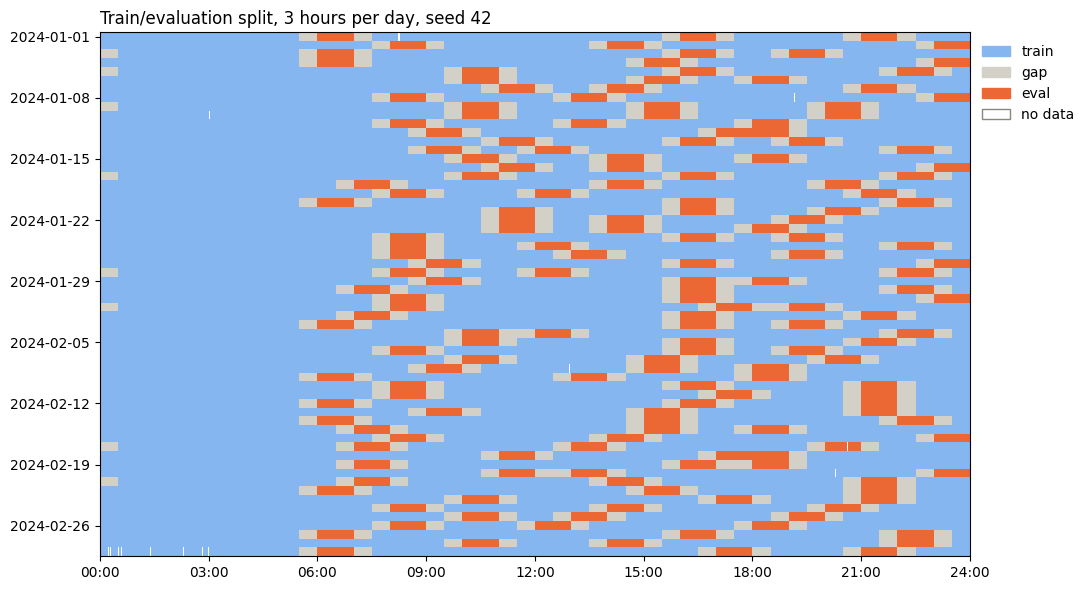

In [9]:
CODES = {"train": 0, "gap": 1, "eval": 2}
first_days = data.index.normalize().unique()[:60]
grid_rows = data[data.index.normalize().isin(first_days)]
slots = ((grid_rows.index - grid_rows.index.normalize()) // step).to_numpy()
grid = np.full((len(first_days), int(pd.Timedelta(days=1) / step)), np.nan)
grid[first_days.get_indexer(grid_rows.index.normalize()), slots] = grid_rows["split"].map(CODES)

cmap = plt.matplotlib.colors.ListedColormap(["#86b6ef", "#d3d1c7", "#eb6834"])
cmap.set_bad("white")
fig, ax = plt.subplots(figsize=(11, 6))
ax.imshow(np.ma.masked_invalid(grid), aspect="auto", cmap=cmap, vmin=0, vmax=2, interpolation="nearest")
ax.set_xticks(np.arange(0, grid.shape[1] + 1, grid.shape[1] // 8),
              [f"{h:02d}:00" for h in range(0, 25, 3)])
ax.set_yticks(range(0, len(first_days), 7), [d.strftime("%Y-%m-%d") for d in first_days[::7]])
handles = [plt.matplotlib.patches.Patch(color=c, label=n)
           for n, c in zip(CODES, ["#86b6ef", "#d3d1c7", "#eb6834"])]
handles.append(plt.matplotlib.patches.Patch(facecolor="white", edgecolor="#888780", label="no data"))
ax.legend(handles=handles, frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.set_title(f"Train/evaluation split, {N_HOURS} hours per day, seed {SEED}", loc="left")
fig.tight_layout()

## 3. Labels and features

The HMM learns from sensor features only; the `label` from `labeled_dataset/` is used to give each hidden state an OPEN rate.
Time of day (`hour_sin`, `hour_cos`) is a feature because heat only counts during daytime in the labels.

In [10]:
from pathlib import Path

from modules.model.hmm import FEATURES, add_time_features, apply_hysteresis, evaluate, walk_forward

labels = pd.concat(
    pd.read_csv(f, index_col="timestamp", parse_dates=["timestamp"],
                usecols=["timestamp", "label", "reason", "utci"], keep_default_na=False)
    for f in sorted(Path("labeled_dataset").glob("*.csv"))
)
data = add_time_features(data.join(labels))
missing = data["label"].isna().sum()
assert missing == 0, f"{missing:,} rows have no label: re-run labeling.ipynb"
data[FEATURES + ["utci", "label", "reason", "split"]].head()

,temperature,humidity,wind_u,wind_v,rain_flag,hour_sin,hour_cos,utci,label,reason,split
timestamp,,,,,,,,,,,
2024-01-01 00:01:00,0.700000,96.0,-0.472809,-0.423235,0.0,0.004363,0.999990,1.934163,CLOSED,,train
2024-01-01 00:01:20,0.723457,96.0,-0.468313,-0.428205,0.0,0.005818,0.999983,1.959623,CLOSED,,train
2024-01-01 00:01:40,0.758025,96.0,-0.428171,-0.313826,0.0,0.007272,0.999974,2.278381,CLOSED,,train
2024-01-01 00:02:00,0.800000,96.0,-0.232483,-0.083174,0.0,0.008727,0.999962,2.404824,CLOSED,,train
2024-01-01 00:02:20,0.871605,96.0,-0.139260,-0.033403,0.0,0.010181,0.999948,2.481504,CLOSED,,train


### Window features

Each 20-second row keeps its timestamp and gains columns summarising the **past** few minutes of sensor data, ending at that row
(e.g. `utci_mean_10m` = mean UTCI over the last 10 minutes, `rain_recency` = 1 while the rain detector is wet, fading over ~5 minutes afterwards).

Only the device's sensors are used: temperature, humidity, wind speed (and direction), the rain detector, and the clock. No barometer and no rain gauge.

- **Past only:** windows look backwards, so each value is what the device can compute from its sensor buffer at that moment.
- **Restart at data gaps:** windows never span a gap between segments.
- **Computed before the split, on the whole stream:** evaluation rows need the same features as training rows, and their history
  (the minutes before an evaluation hour) is sensor data the device would have. No labels are used.
- **Longest window (15 min) ≤ the split's gap (`GAP_MINUTES`),** so a training row's history never reaches into an evaluation hour.
- `warmup` marks the first 15 minutes of each segment, where the longest windows are still filling.

In [11]:
from modules.dataset.windowing import MAX_WINDOW, WINDOW_FEATURES, add_window_features

assert MAX_WINDOW <= pd.Timedelta(minutes=GAP_MINUTES), "longest window must not exceed the split gap"
data = add_window_features(data)
print("window features:", WINDOW_FEATURES)
print(f"warm-up rows: {data['warmup'].mean():.2%}")
data[WINDOW_FEATURES].describe().T[["mean", "std", "min", "max"]].round(2)

window features: ['utci_mean_10m', 'utci_max_10m', 'wet_share_5m', 'wet_share_10m', 'rain_recency', 'humidity', 'humidity_chg_15m', 'wind_mean_5m', 'wind_max_5m', 'hour_sin', 'hour_cos']
warm-up rows: 0.17%


,mean,std,min,max
utci_mean_10m,13.40,10.80,-24.75,38.03
utci_max_10m,14.74,10.22,-21.00,38.61
wet_share_5m,0.06,0.23,0.00,1.00
wet_share_10m,0.06,0.23,0.00,1.00
rain_recency,0.07,0.25,0.00,1.00
humidity,66.83,22.58,10.00,99.90
humidity_chg_15m,-0.00,2.39,-37.60,42.40
wind_mean_5m,1.45,1.13,0.00,8.66
wind_max_5m,2.09,1.47,0.00,13.90
hour_sin,0.00,0.71,-1.00,1.00


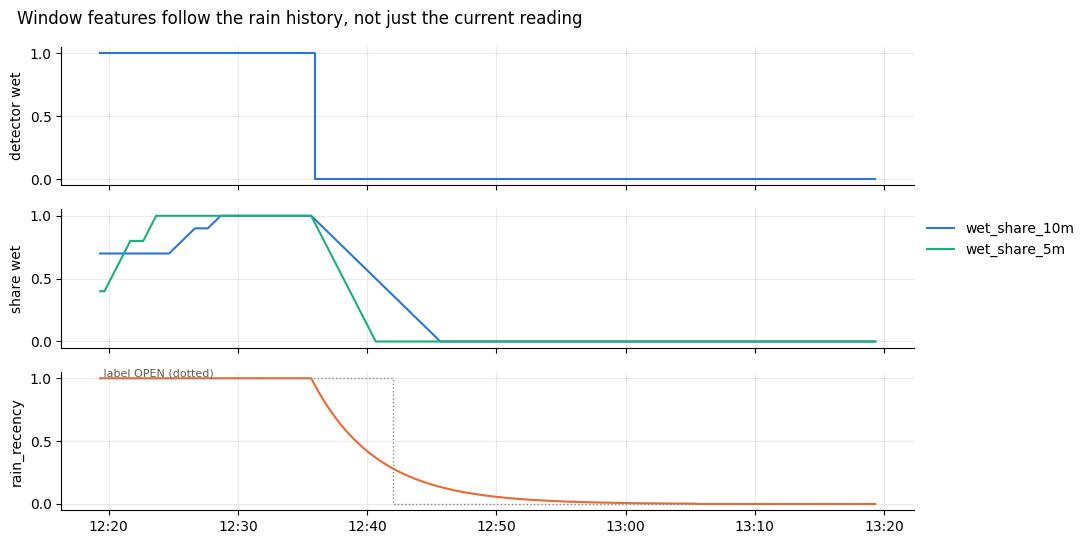

In [12]:
# How the rain history behaves around one rain event
wet_rows = data.index[data["wet_share_5m"] > 0]
t0 = wet_rows[len(wet_rows) // 2] - pd.Timedelta(minutes=20)
view = data.loc[t0:t0 + pd.Timedelta(minutes=60)]

fig, axes = plt.subplots(3, 1, figsize=(11, 5.5), sharex=True)
axes[0].step(view.index, (view["rain_flag"] > 0).astype(int), where="post", color="#2a78d6")
axes[0].set_ylabel("detector wet")
axes[1].plot(view.index, view["wet_share_10m"], color="#2a78d6", label="wet_share_10m")
axes[1].plot(view.index, view["wet_share_5m"], color="#1baf7a", label="wet_share_5m")
axes[1].set_ylabel("share wet")
axes[2].plot(view.index, view["rain_recency"], color="#eb6834")
axes[2].set_ylabel("rain_recency")
axes[2].step(view.index, (view["label"] == "OPEN").astype(int), where="post", color="#888780", lw=1, ls=":")
axes[2].text(view.index[0], 1, " label OPEN (dotted)", va="bottom", fontsize=8, color="#5f5e5a")
for ax in axes:
    ax.grid(alpha=0.25)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[1].legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
axes[-1].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M"))
fig.suptitle("Window features follow the rain history, not just the current reading", x=0.02, ha="left")
fig.tight_layout()

## 4. Walk-forward evaluation (deployment simulation)

Simulates the umbrella in the field, so the score is what to expect in reality:

1. **Retrain every `RETRAIN_DAYS`** on the `train` rows of the last `WINDOW_DAYS` days that have data, never on anything later.
   Each retrain warm-starts from the previous model (`WARM_ITER` EM iterations); the first fit keeps the best of `N_RESTARTS` random starts.
   If a retrain fails, the previous model stays in service.
2. **Run the model forward over the next days' sensor stream**, minute by minute, without looking ahead (forward filtering).
   Readings just before an evaluation hour serve as context, as they would on the device.
3. **Score the `eval` rows** against the label `HORIZON_MINUTES` ahead, so the umbrella has time to move.

The baseline **persistence** predicts that the label stays what it is now. The labels are computed from current sensors, so this is a strong baseline: the HMM is only worth deploying if it beats it.

In [13]:
N_STATES = 10
HORIZON_MINUTES = 5
INITIAL_DAYS = 14     # days of history before the first evaluation
RETRAIN_DAYS = 7      # retrain once a week
WINDOW_DAYS = 60      # train on the latest 60 days with data, so each model fits the season; None = all
N_ITER = 50           # EM iterations for the first fit
WARM_ITER = 10        # EM iterations per weekly retrain
N_RESTARTS = 3
USE_WINDOWS = True    # use the window features (recommended); False = current readings only
USE_UTCI = False      # only without windows: add raw UTCI (noisy at 20 s)
TUNE_THRESHOLD = True # each retrain picks the OPEN threshold that maximises F1 on its training rows
CLOSE_MARGIN = 0.2    # hysteresis: open at the threshold, close only below threshold - CLOSE_MARGIN
MIN_HOLD_MINUTES = 3  # after moving, the umbrella holds its position at least this long

features = WINDOW_FEATURES if USE_WINDOWS else FEATURES + (["utci"] if USE_UTCI else [])
print("features:", features)
predictions, folds = walk_forward(
    data, features=features, n_states=N_STATES, horizon_minutes=HORIZON_MINUTES,
    initial_days=INITIAL_DAYS, retrain_days=RETRAIN_DAYS, window_days=WINDOW_DAYS,
    n_iter=N_ITER, warm_iter=WARM_ITER, n_restarts=N_RESTARTS, seed=SEED,
    tune_threshold=TUNE_THRESHOLD,
)
predictions["open"] = apply_hysteresis(predictions, CLOSE_MARGIN, MIN_HOLD_MINUTES)
print(f"{len(folds)} folds, {len(predictions):,} scored rows")
print(folds["status"].str.split(" (", regex=False).str[0].value_counts().to_string())

features: ['utci_mean_10m', 'utci_max_10m', 'wet_share_5m', 'wet_share_10m', 'rain_recency', 'humidity', 'humidity_chg_15m', 'wind_mean_5m', 'wind_max_5m', 'hour_sin', 'hour_cos']


c:\Users\andro\anaconda3\envs\weather_env\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
walk-forward:   0%|          | 0/78 [00:00<?, ?fold/s]Model is not converging.  Current: 51672.4337354746 is not greater than 51697.89900140123. Delta is -25.46526592662849
fold 0: fresh fit
walk-forward: 100%|██████████| 78/78 [1:20:40<00:00, 62.05s/fold]


78 folds, 290,682 scored rows
status
warm start            76
fresh fit              1
refit from scratch     1


## 5. Results

In [14]:
results = pd.DataFrame({
    "HMM": evaluate(predictions["target"], predictions["p_open"], decision=predictions["open"]),
    "persistence": evaluate(predictions["target"], predictions["now"]),
}).T
results.round(3)

,rows,open_share,accuracy,balanced_accuracy,precision,recall,f1,brier,roc_auc
HMM,290682.0,0.163,0.902,0.845,0.676,0.760,0.715,0.070,0.939
persistence,290682.0,0.163,0.985,0.973,0.953,0.954,0.954,0.015,0.973


### Recall by reason

Share of rows that should be OPEN, by why, that each method gets right.

In [15]:
by_reason = {}
for reason, rows in predictions[predictions["target"] == 1].groupby("reason"):
    by_reason[reason] = {"rows": len(rows),
                         "HMM": (rows["p_open"] >= 0.5).mean(),
                         "persistence": (rows["now"] >= 0.5).mean()}
pd.DataFrame(by_reason).T.round(3)

,rows,HMM,persistence
heat,24498.0,0.428,0.988
heat+rain,1181.0,0.920,0.983
rain,21651.0,0.882,0.915


### Does the umbrella open and close correctly?

Looks at the umbrella's actions rather than individual rows:

- **Moment by moment:** how often it is open or closed when it should be.
- **Per period that should be OPEN:** did it open at all, how late (minutes after the period started), what share of the period it was open,
  and at the end of the period whether it had already closed too early or, if not, how late it closed.
  Delays are only measured when the start or end falls inside an evaluation stretch.
- **Unneeded movement:** false openings (opened while it should stay closed the whole time) and switches per 24 h, compared with how often the labels switch.

Persistence opens and closes `HORIZON_MINUTES` late by construction, so its delays show the cost of not anticipating.

In [16]:
from modules.model.hmm import action_episodes, evaluate_actions

actions = pd.DataFrame({
    "HMM": evaluate_actions(predictions, "open"),
    "persistence": evaluate_actions(predictions, "now"),
})
actions.round(3)

,HMM,persistence
open when should be open,0.760,0.954
closed when should be closed,0.929,0.991
open when should be closed,0.071,0.009
closed when should be open,0.240,0.046
periods that should be open,415.000,415.000
periods it opened for,0.817,0.973
median open delay (min),0.000,5.000
closed too early,0.034,0.000
median close delay (min),9.667,5.000
share of open period covered,0.720,0.834


In [17]:
episodes = action_episodes(predictions, "open")
should_open = episodes[episodes["kind"] == "should open"]
should_open.groupby("reason").agg(
    periods=("start", "size"),
    opened=("opened", "mean"),
    covered=("covered", "mean"),
    median_open_delay_min=("open_delay_min", "median"),
    closed_too_early=("closed_early", lambda s: s.astype(float).mean()),
    median_close_delay_min=("close_delay_min", "median"),
).round(3)

,periods,opened,covered,median_open_delay_min,closed_too_early,median_close_delay_min
reason,,,,,,
heat,150,0.573333,0.559,0.0,0.267,NaN
heat+rain,10,1.0,0.874,2.5,0.000,4.667
rain,255,0.952941,0.809,0.0,0.008,9.667


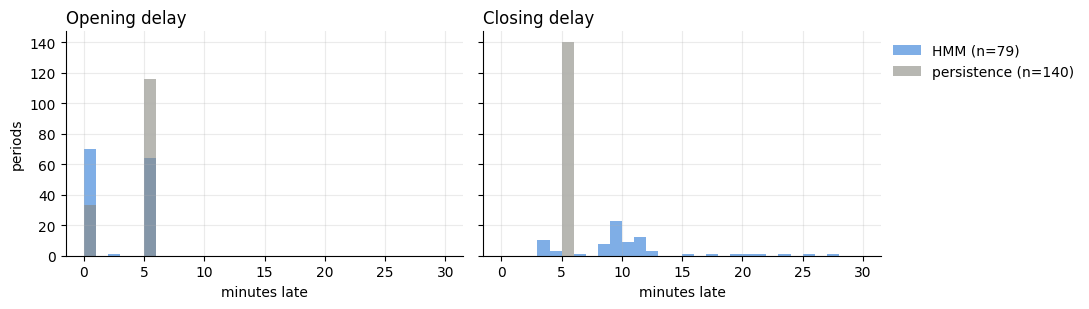

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, column, title in [(axes[0], "open_delay_min", "Opening delay"),
                          (axes[1], "close_delay_min", "Closing delay")]:
    for method, col, color in [("HMM", "open", "#2a78d6"), ("persistence", "now", "#888780")]:
        ep = action_episodes(predictions, col)
        delays = ep.loc[ep["kind"] == "should open", column].dropna()
        ax.hist(delays, bins=np.arange(0, 31, 1), color=color, alpha=0.6,
                label=f"{method} (n={len(delays)})")
    ax.set_title(title, loc="left")
    ax.set_xlabel("minutes late")
    ax.grid(alpha=0.25)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("periods")
axes[1].legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.tight_layout()

### F1 by month

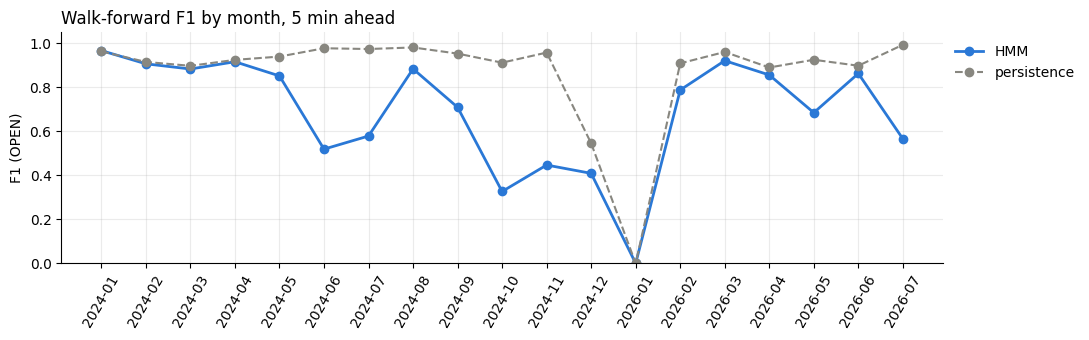

In [19]:
monthly = pd.DataFrame({
    method: predictions.groupby(predictions.index.to_period("M")).apply(
        lambda g, c=column: evaluate(g["target"], g[c])["f1"])
    for method, column in [("HMM", "open"), ("persistence", "now")]
})

fig, ax = plt.subplots(figsize=(11, 3.5))
x = monthly.index.astype(str)
ax.plot(x, monthly["HMM"], marker="o", color="#2a78d6", lw=2, label="HMM")
ax.plot(x, monthly["persistence"], marker="o", color="#888780", lw=1.5, ls="--", label="persistence")
ax.set_ylim(0, 1.05)
ax.set_ylabel("F1 (OPEN)")
ax.tick_params(axis="x", rotation=60)
ax.grid(alpha=0.25)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.set_title(f"Walk-forward F1 by month, {HORIZON_MINUTES} min ahead", loc="left")
fig.tight_layout()

In [20]:
folds.head()

,train_from,eval_from,eval_to,train_rows,eval_rows,status,log_likelihood_per_row,state_open_rates,threshold
fold,,,,,,,,,
0,2024-01-01,2024-01-15,2024-01-21,45519,3780,fresh fit,1.206830,"[0.0, 0.058, 0.89, 0.0, 0.002, 0.005, 0.005, 0...",0.85
1,2024-01-01,2024-01-22,2024-01-28,68199,3780,warm start,0.064762,"[0.002, 0.174, 0.929, 0.0, 0.008, 0.006, 0.006...",0.90
2,2024-01-01,2024-01-29,2024-02-04,90879,3780,warm start,0.304922,"[0.001, 0.167, 0.93, 0.0, 0.01, 0.005, 0.005, ...",0.90
3,2024-01-01,2024-02-05,2024-02-11,113559,3780,warm start,-0.098394,"[0.001, 0.173, 0.93, 0.002, 0.014, 0.006, 0.00...",0.90
4,2024-01-01,2024-02-12,2024-02-18,136233,3768,warm start,-0.293059,"[0.001, 0.207, 0.936, 0.001, 0.015, 0.01, 0.01...",0.90


## 6. Final model for deployment

Fits the model on the latest `WINDOW_DAYS` of training rows and saves it with its scaler and per-state OPEN rates.
`predict_open(bundle, stream)` gives P(OPEN `HORIZON_MINUTES` ahead) for new sensor rows.

In [21]:
import joblib

from modules.model.hmm import predict_open, train_final

bundle = train_final(data, features=features, n_states=N_STATES, horizon_minutes=HORIZON_MINUTES,
                     window_days=WINDOW_DAYS, n_iter=N_ITER, n_restarts=N_RESTARTS, seed=SEED,
                     tune_threshold=TUNE_THRESHOLD)
bundle["close_margin"] = CLOSE_MARGIN  # device: open at p >= threshold, close below threshold - margin
bundle["min_hold_minutes"] = MIN_HOLD_MINUTES
Path("models").mkdir(exist_ok=True)
joblib.dump(bundle, "models/umbrella_hmm.joblib")
print(f"trained on {bundle['train_rows']:,} rows, {bundle['trained_from']:%Y-%m-%d} → {bundle['trained_to']:%Y-%m-%d}")
print("OPEN rate per state:", bundle["state_open_rates"].round(3), "| threshold:", bundle["threshold"])
predict_open(bundle, data.tail(5))

Model is not converging.  Current: 125392.85157594363 is not greater than 125393.03733045068. Delta is -0.1857545070524793
Model is not converging.  Current: 206298.32986013652 is not greater than 206298.79383721348. Delta is -0.4639770769572351


trained on 195,305 rows, 2026-05-09 → 2026-07-07
OPEN rate per state: [0.023 0.003 1.    0.023 0.005 0.074 0.15  0.728 0.003 0.014] | threshold: 0.7


timestamp
2026-07-07 23:57:20    0.014086
2026-07-07 23:57:40    0.014095
2026-07-07 23:58:00    0.014095
2026-07-07 23:58:20    0.014095
2026-07-07 23:58:40    0.014095
Name: p_open, dtype: float64